# ML-05b (C#) : Séries temporelles classiques — stationnarité, ACF/PACF, ARIMA/SARIMA, lissage exponentiel

> **Socle statistique.** Ce notebook pose les fondations que [ML-05-TimeSeries-CSharp](ML-05-TimeSeries-CSharp.ipynb) (SSA, ML.NET) applique en boîte noire et que [ML-05-TimeSeries-Python](ML-05-TimeSeries-Python.ipynb) (STL + SARIMA) applique mécaniquement : **tester la stationnarité**, **lire une ACF/PACF**, **ajuster un ARIMA**, **comprendre pourquoi différencier**, et **comparer honnêtement** ARIMA, lissage exponentiel et baseline naïve.



## Objectifs d'apprentissage

À l'issue de ce notebook, vous saurez :

1. **Décomposer** une série en tendance + saisonnalité + résidu (`seasonal_decompose`), et lire chaque composante.
2. **Tester la stationnarité** avec ADF (H0, p-value, conclusion écrite) et **différencier** pour la rétablir.
3. **Lire une ACF/PACF** pour identifier les ordres `p` et `q` (les barres hors bande de confiance), y compris sur un AR(2) synthétique.
4. **Ajuster un SARIMA** depuis la lecture ACF/PACF, **diagnostiquer** les résidus (ACF plate + Ljung-Box) et **prévoir** avec intervalle de confiance.
5. **Lisser** par simple / Holt / Holt-Winters, et savoir quand le lissage égale ARIMA à moindre coût intellectuel.
6. **Comparer honnêtement** (ARIMA vs Holt-Winters vs naïf) sur un backtest glissant — la baseline naïve qui gagne parfois **est** la leçon.

**Relation aux autres notebooks** : ML-05 (SSA) = le même problème en ML.NET ; ML-05-TimeSeries-Python = l'application STL+SARIMA ; ce notebook = le **pourquoi** statistique que les deux supposent. Du côté quant, les notebooks HAR de QuantConnect poussent la même famille vers les features modernes (voir la conclusion).

**Navigation** : [Version Python](ML-05b-Series-Temporelles-Classiques-Python.ipynb) · [Index](README.md).

**Prérequis** : statistiques élémentaires, tableaux, régression ; **durée indicative** : 90 minutes.


**Politique de portage** : statsmodels conserve les vraies décompositions, tests, SARIMA/ARIMA et lissages via Python.NET. SSA de ML.NET est un autre modèle et ne fournit pas cette leçon exacte. Les données, grilles, métriques, backtests et figures sont orchestrés en C#. Les tirages NumPy servent à conserver les mêmes innovations synthétiques. Aucun script Python ne rejoue le carnet entier.


In [1]:
// Les fonctions C# convertissent les tableaux et appellent les vraies API statsmodels.
// Chaque conversion et Dispose de PyObject reste sous GIL ; aucune erreur de modèle ne devient un repli naïf.
#r "nuget: pythonnet,3.1.0"
#load "../../Config/PythonNetLoader.cs"
using System;
using System.IO;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using System.Text.Json;
using System.Security.Cryptography;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "statsmodels");
    PythonEngine.BeginAllowThreads();
}

PyObject JsonPy<T>(T value)
{
    dynamic json = Py.Import("json");
    return json.loads(JsonSerializer.Serialize(value));
}

PyObject ArrayPy(double[] values)
{
    using (Py.GIL())
    {
        dynamic np = Py.Import("numpy");
        using PyObject parsed = JsonPy(values);
        return np.array(parsed, dtype: np.float64);
    }
}

double[] Vector(PyObject values)
{
    using (Py.GIL())
    {
        using PyObject list = ((dynamic)values).tolist();
        return list.As<double[]>();
    }
}

double[][] Matrix(PyObject values)
{
    using (Py.GIL())
    {
        using PyObject list = ((dynamic)values).tolist();
        return list.As<double[][]>();
    }
}

(double Statistic, double PValue, int Lags, int N) Adf(double[] values)
{
    using (Py.GIL())
    {
        dynamic st = Py.Import("statsmodels.tsa.stattools");
        using PyObject a = ArrayPy(values);
        using PyObject r = st.adfuller(a);
        return (r.GetItem(0).As<double>(), r.GetItem(1).As<double>(), r.GetItem(2).As<int>(), r.GetItem(3).As<int>());
    }
}

(double[] Acf, double[] Pacf) Correlations(double[] values, int lags)
{
    using (Py.GIL())
    {
        dynamic st = Py.Import("statsmodels.tsa.stattools");
        using PyObject a = ArrayPy(values);
        using PyObject x = st.acf(a, nlags: lags);
        using PyObject p = st.pacf(a, nlags: lags, method: "ywm");
        return (Vector(x), Vector(p));
    }
}

PyObject FitSarima(double[] values, int[] order, int[] seasonal)
{
    using (Py.GIL())
    {
        dynamic sm = Py.Import("statsmodels.tsa.statespace.sarimax");
        using PyObject a = ArrayPy(values);
        using PyObject o = JsonPy(order);
        using PyObject s = JsonPy(seasonal);
        using PyObject model = sm.SARIMAX(a, order: o, seasonal_order: s);
        return ((dynamic)model).fit(disp: false);
    }
}

PyObject FitSmoothing(double[] values, string kind)
{
    using (Py.GIL())
    {
        dynamic sm = Py.Import("statsmodels.tsa.holtwinters");
        using PyObject a = ArrayPy(values);
        using PyObject model = kind == "HW" ? sm.ExponentialSmoothing(a, trend: "add", seasonal: "add", seasonal_periods: 7) : kind == "Holt" ? sm.Holt(a) : sm.SimpleExpSmoothing(a);
        return ((dynamic)model).fit();
    }
}

double Aic(PyObject model)
{
    using (Py.GIL())
    {
        return ((PyObject)((dynamic)model).aic).As<double>();
    }
}

double[] Forecast(PyObject model, int steps)
{
    using (Py.GIL())
    {
        using PyObject f = ((dynamic)model).forecast(steps);
        return Vector(f);
    }
}

(double[] Mean, double[][] Interval) ForecastInterval(PyObject model, int steps)
{
    using (Py.GIL())
    {
        using PyObject f = ((dynamic)model).get_forecast(steps);
        using PyObject mean = ((dynamic)f).predicted_mean;
        using PyObject ci = ((dynamic)f).conf_int(alpha: .05);
        return (Vector(mean), Matrix(ci));
    }
}

double[][] Decompose(double[] values, int period)
{
    using (Py.GIL())
    {
        dynamic sm = Py.Import("statsmodels.tsa.seasonal");
        using PyObject a = ArrayPy(values);
        using PyObject d = sm.seasonal_decompose(a, model: "additive", period: period);
        return new[]
        {
            "observed",
            "trend",
            "seasonal",
            "resid"
        }.Select(key =>
        {
            using PyObject v = d.GetAttr(key);
            return Vector(v);
        }).ToArray();
    }
}

double[] Difference(double[] values, int lag = 1) => Enumerable.Range(lag, values.Length - lag).Select(i => values[i] - values[i - lag]).ToArray();
double Mape(double[] truth, double[] prediction)
{
    if (truth.Length == 0 || truth.Length != prediction.Length || truth.Any(x => !double.IsFinite(x) || x == 0) || prediction.Any(x => !double.IsFinite(x)))
        throw new ArgumentException("MAPE : dimensions, valeurs finies et dénominateurs non nuls requis.");
    return truth.Zip(prediction, (x, y) => Math.Abs((x - y) / x)).Average() * 100;
}

double MeanFinite(double[] a) => a.Where(double.IsFinite).Average();
double StdFinite(double[] a)
{
    var b = a.Where(double.IsFinite).ToArray();
    double m = b.Average();
    return Math.Sqrt(b.Sum(x => (x - m) * (x - m)) / (b.Length - 1));
}

using (Py.GIL())
{
    dynamic sys = Py.Import("sys"), sm = Py.Import("statsmodels"), np = Py.Import("numpy"), sp = Py.Import("scipy");
    Console.WriteLine($".NET {Environment.Version} | Python.NET {typeof(PythonEngine).Assembly.GetName().Version} | CPython {sys.version.split()[0]} | statsmodels {sm.__version__} | NumPy {np.__version__} | SciPy {sp.__version__}");
}

Console.WriteLine("Statsmodels réel : décomposition, ADF/ACF/PACF, SARIMA/ARIMA et trois lissages ; orchestration et métriques C# prêtes.");
(double[] Values, double[][] CenteredIntervals) CorrelationInterval(double[] values, int lags, bool partial = false)
{
    using (Py.GIL())
    {
        dynamic st = Py.Import("statsmodels.tsa.stattools");
        using PyObject a = ArrayPy(values);
        using PyObject r = partial ? st.pacf(a, nlags: lags, method: "ywm", alpha: .05) : st.acf(a, nlags: lags, alpha: .05);
        using PyObject x = r.GetItem(0);
        using PyObject c = r.GetItem(1);
        var v = Vector(x);
        var ci = Matrix(c);
        for (int i = 0; i < ci.Length; i++)
            for (int j = 0; j < 2; j++)
                ci[i][j] -= v[i];
        return (v, ci);
    }
}


Installed Packages pythonnet, 3.1.0

.NET 10.0.14 | Python.NET 3.1.0.0 | CPython 3.13.16 | statsmodels 0.14.6 | NumPy 2.4.4 | SciPy 1.17.0


Statsmodels réel : décomposition, ADF/ACF/PACF, SARIMA/ARIMA et trois lissages ; orchestration et métriques C# prêtes.


### Figures statiques du parcours

Les six expériences graphiques du source sont conservées sous forme SVG, avec panneaux séparés, axes, unités, légendes et zones de confiance. Le rendu ne dépend ni de JavaScript ni d’un CDN.


In [2]:
record PlotSvg(string Content);
Formatter.Register<PlotSvg>((value, writer) => writer.Write(value.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(PlotSvg), "image/svg+xml");
// Le MIME image conserve les figures dans les lecteurs statiques de notebooks.
void AfficherSvg(PlotSvg figure)
{
    display(figure, "image/svg+xml");
}

string F(double x) => x.ToString("0.###", CultureInfo.InvariantCulture);
string Esc(string s) => System.Security.SecurityElement.Escape(s) ?? "";
string Plot(string title, (string Name, double[] Y, string Color)[] series, string xLabel = "indice quotidien", string yLabel = "ventes", double[][] interval = null, int intervalOffset = 0, double? band = null)
{
    int length = series.Max(s => s.Y.Length);
    var finite = series.SelectMany(s => s.Y).Where(double.IsFinite).ToList();
    if (interval != null)
        finite.AddRange(interval.SelectMany(x => x).Where(double.IsFinite));
    if (band.HasValue)
    {
        finite.Add(band.Value);
        finite.Add(-band.Value);
    }

    double min = finite.Min(), max = finite.Max();
    if (max <= min)
        max = min + 1;
    double pad = (max - min) * .08;
    min -= pad;
    max += pad;
    double X(int i) => 65 + 720.0 * i / Math.Max(1, length - 1);
    double Y(double v) => 285 - 225 * (v - min) / (max - min);
    var b = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 820 365' role='img' aria-label='{Esc(title)}'><rect width='820' height='365' fill='white'/><text x='410' y='24' text-anchor='middle' font-family='sans-serif' font-size='16'>{Esc(title)}</text>");
    for (int k = 0; k <= 4; k++)
    {
        double v = min + (max - min) * k / 4.0, y = Y(v);
        b.Append($"<path d='M65 {F(y)}H785' stroke='#ddd'/><text x='59' y='{F(y + 4)}' text-anchor='end' font-size='11'>{F(v)}</text>");
    }

    for (int k = 0; k <= 5; k++)
    {
        int i = (int)Math.Round((length - 1) * k / 5.0);
        double x = X(i);
        b.Append($"<path d='M{F(x)} 285v5' stroke='#333'/><text x='{F(x)}' y='307' text-anchor='middle' font-size='11'>{i}</text>");
    }

    b.Append($"<path d='M65 60V285H785' fill='none' stroke='#333'/><text x='420' y='327' text-anchor='middle' font-size='12'>{Esc(xLabel)}</text><text x='16' y='173' transform='rotate(-90 16 173)' text-anchor='middle' font-size='12'>{Esc(yLabel)}</text>");
    if (band.HasValue)
        foreach (double v in new[]
        {
            -band.Value,
            band.Value
        }

        )
            b.Append($"<path d='M65 {F(Y(v))}H785' stroke='#789' stroke-dasharray='4 3'/>");
    if (interval != null)
    {
        var points = interval.Select((a, i) => (x: X(i + intervalOffset), y: Y(a[0]))).Concat(interval.Select((a, i) => (x: X(i + intervalOffset), y: Y(a[1]))).Reverse().Take(interval.Length));
        b.Append("<polygon fill='#e2e9f4' points='" + string.Join(" ", points.Select(p => $"{F(p.x)},{F(p.y)}")) + "'/>");
    }

    int legendX = 70;
    foreach (var s in series)
    {
        var path = new StringBuilder();
        bool active = false;
        for (int i = 0; i < s.Y.Length; i++)
        {
            double v = s.Y[i];
            if (!double.IsFinite(v))
            {
                active = false;
                continue;
            }

            path.Append($"{(active ? "L" : "M")}{F(X(i))} {F(Y(v))}");
            active = true;
        }

        b.Append($"<path d='{path}' fill='none' stroke='{s.Color}' stroke-width='1.5'/><path d='M{legendX} 347h18' stroke='{s.Color}' stroke-width='2'/><text x='{legendX + 23}' y='351' font-size='11'>{Esc(s.Name)}</text>");
        legendX += Math.Min(220, 38 + s.Name.Length * 6);
    }

    return b.Append("</svg>").ToString();
}

string Stack(string[] charts)
{
    const int width = 820, panelHeight = 365;
    int height = panelHeight * charts.Length;
    var result = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/>");
    // Chaque panneau garde ses axes et son viewBox dans une racine SVG unique.
    for (int i = 0; i < charts.Length; i++)
    {
        result.Append(charts[i].Replace("<svg ", $"<svg x='0' y='{i * panelHeight}' width='{width}' height='{panelHeight}' "));
    }

    return result.Append("</svg>").ToString();
}

void Show(string title, (string Name, double[] Y, string Color)[] series, string xLabel = "indice quotidien", string yLabel = "ventes", double[][] interval = null, int intervalOffset = 0, double? band = null) => AfficherSvg(new PlotSvg(Plot(title, series, xLabel, yLabel, interval, intervalOffset, band)));
Console.WriteLine("Rendu SVG statique : fonds blancs, axes et unités, légendes et intervalle ; aucune ressource externe.");


Rendu SVG statique : fonds blancs, axes et unités, légendes et intervalle ; aucune ressource externe.


## Partie 1 : Décomposition — tendance + saisonnalité + résidu

On commence par **voir** ce qui compose une série temporelle. Le modèle additif classique est :

```
série(t) = tendance(t) + saisonnalité(t) + résidu(t)
```

`statsmodels.seasonal_decompose` sépare ces trois composantes. On le démontre d'abord sur une série **synthétique franche** (tendance + saisonnalité 12 + bruit), pour que les trois composantes soient lisibles, puis sur la **vraie série du dépôt** (`daily-sales.csv`, celle que ML-05 utilise).

### Exemple guidé — série synthétique franche

La cellule ci-dessous fabrique la série : une tendance linéaire de pente 0,4, une saisonnalité sinusoïdale de période 12, et un bruit gaussien.

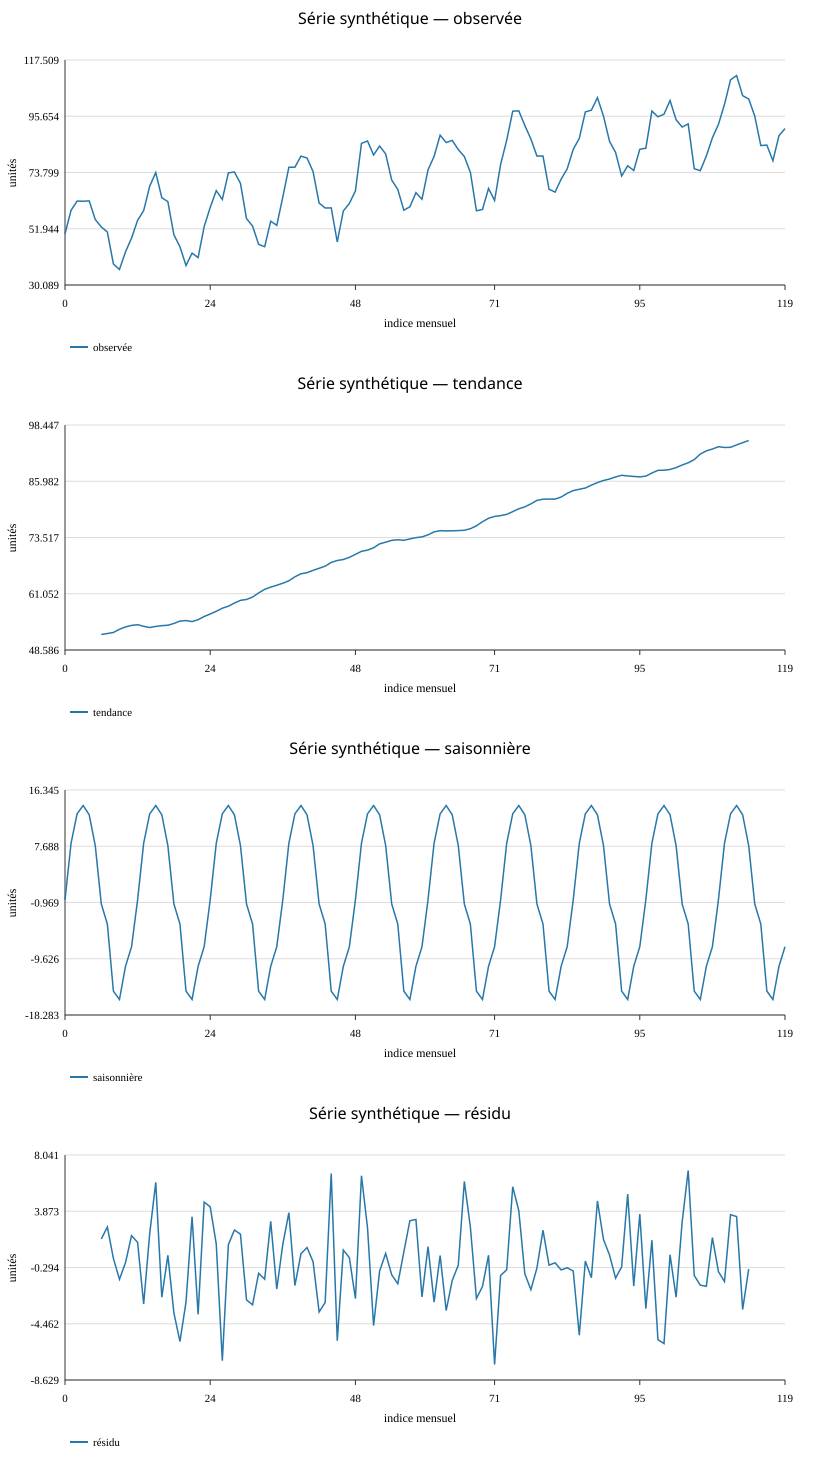

120 mois, période 12, pente 0,4/mois ; tendance moyenne 73.2, amplitude saisonnière 29.9, résidu moyenne 0.053, écart-type 3.07


In [3]:
// Le générateur ajoute séparément tendance, saison annuelle et bruit de graine fixe.
// La décomposition retrouve des composantes estimées ; leurs moments ne démontrent pas à eux seuls la stationnarité.
double[] noise;
using (Py.GIL())
{
    dynamic np = Py.Import("numpy");
    using PyObject z = np.random.default_rng(7).normal(0.0, 4.0, 120);
    noise = Vector(z);
}

var synth = Enumerable.Range(0, 120).Select(t => 50 + .4 * t + 15 * Math.Sin(2 * Math.PI * t / 12) + noise[t]).ToArray();
var synthParts = Decompose(synth, 12);
var partNames = new[]
{
    "observée",
    "tendance",
    "saisonnière",
    "résidu"
};
AfficherSvg(new PlotSvg(Stack(synthParts.Select((v, i) => Plot("Série synthétique — " + partNames[i], new[] { (partNames[i], v, "#2677aa") }, "indice mensuel", "unités")).ToArray())));
Console.WriteLine($"120 mois, période 12, pente 0,4/mois ; tendance moyenne {MeanFinite(synthParts[1]):F1}, amplitude saisonnière {synthParts[2].Max() - synthParts[2].Min():F1}, résidu moyenne {MeanFinite(synthParts[3]):F3}, écart-type {StdFinite(synthParts[3]):F2}");


### Interprétation de la décomposition synthétique

La tendance croît de **0,4 par mois** dans le générateur. La décomposition donne une tendance moyenne voisine de 73 et une amplitude saisonnière proche de 30 ; les valeurs exactes sont imprimées. La composante saisonnière est périodique par construction de l'algorithme : cela ne prouve pas une périodicité parfaite d'une série observée. Le résidu, de moyenne proche de zéro et d'écart-type proche de 3, reste de l'ordre du bruit injecté (écart-type 4), dont la décomposition absorbe une partie. Une moyenne et une variance empiriques ne suffisent pas à établir la stationnarité ; celle du bruit est ici une hypothèse du générateur.

La prévision cherche à exploiter tendance et saisonnalité sans confondre le bruit du tirage avec un signal prévisible.


### Application à la série fournie dans le dépôt — daily-sales.csv

On utilise exactement le fichier de ventes quotidiennes partagé avec ML-05 : période 2023–2024, cycle hebdomadaire (période 7). Le fichier est une donnée pédagogique du dépôt ; son utilisation ne constitue pas une affirmation sur une provenance commerciale indépendante. La décomposition est calculée sur l'entraînement 2023 seulement.


daily-sales.csv SHA256 072b30f55ac726f7bfe31cfb78fd5e085669d1bc992d0d5459db7e09d49ae049


2023-01-01 → 2024-12-31 : 731 jours ; train2023 365, moyenne 124.5 ; test2024 366, moyenne 174.3 ; croissance 40.0 %


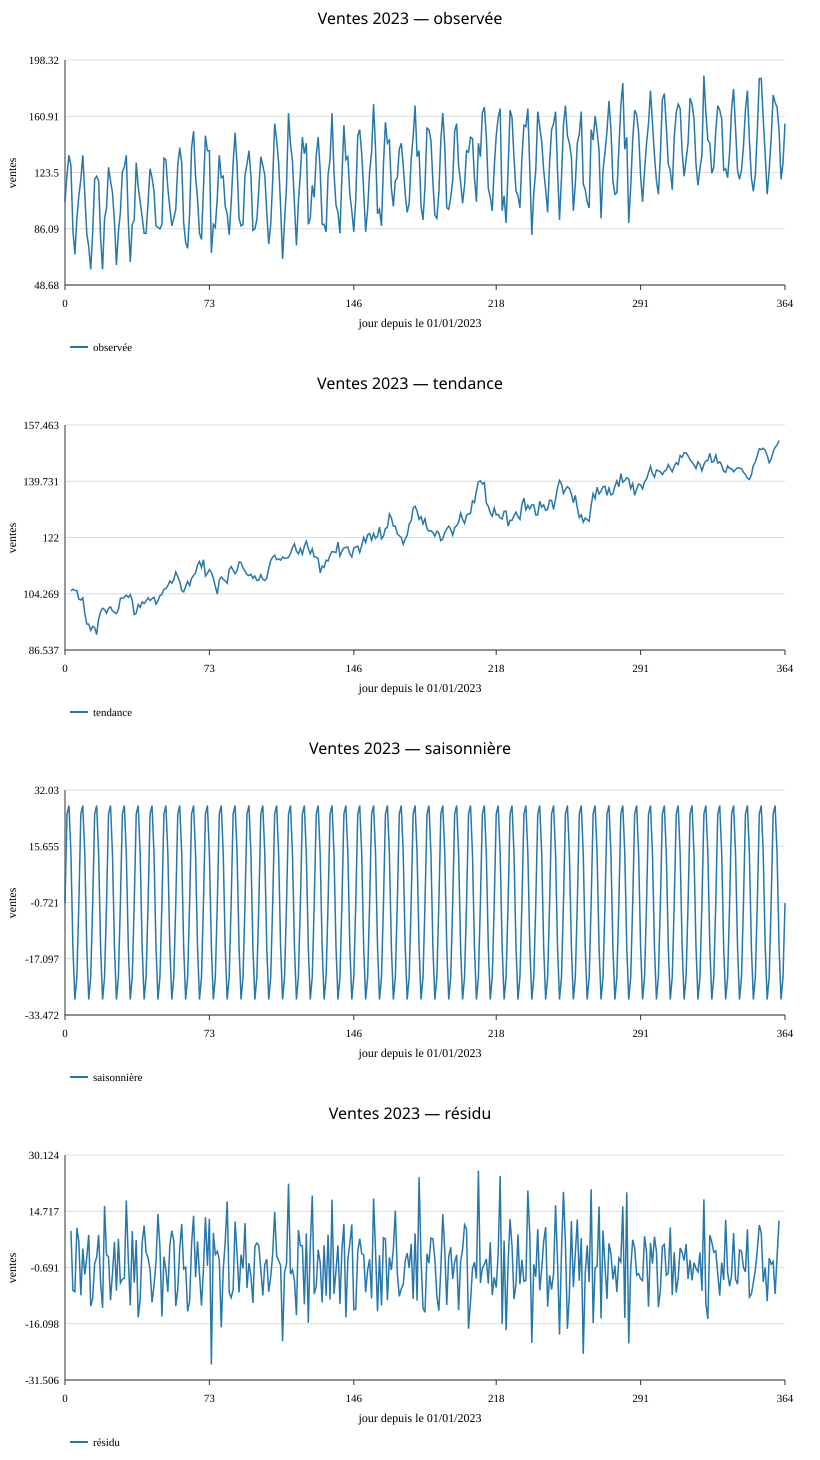

Tendance 2023 aux extrémités disponibles : 105.1 → 152.6


Vecteur Sales float64 little-endian SHA256 71218ba0d8693c1d0a3ad056c3e7ca009986e6c106e1ff05306207e2f7b7383f ; somme 109226 ; première vente 104


In [4]:
// Le CSV est lu par noms de colonnes pour ne pas confondre Sales et Year.
// Le tri et les jours consécutifs sont contrôlés avant le split2023/2024 et les décompositions sur train.
var csv = File.ReadAllLines("daily-sales.csv");
var columns = csv[0].Split(',');
int dateColumn = Array.IndexOf(columns, "Date"), salesColumn = Array.IndexOf(columns, "Sales");
if (dateColumn < 0 || salesColumn < 0)
    throw new FormatException("Colonnes Date et Sales requises.");
var records = csv.Skip(1).Where(x => !string.IsNullOrWhiteSpace(x)).Select(line =>
{
    var fields = line.Split(',');
    return (Date: DateTime.Parse(fields[dateColumn], CultureInfo.InvariantCulture), Sales: double.Parse(fields[salesColumn], CultureInfo.InvariantCulture));
}).OrderBy(x => x.Date).ToArray();
if (records.Any(x => !double.IsFinite(x.Sales)) || records.Zip(records.Skip(1), (a, b) => (b.Date - a.Date).Days).Any(d => d != 1))
    throw new Exception("Ventes : données finies et jours consécutifs requis.");
var sales = records.Select(x => x.Sales).ToArray();
var train = records.Where(x => x.Date.Year == 2023).Select(x => x.Sales).ToArray();
var test = records.Where(x => x.Date.Year == 2024).Select(x => x.Sales).ToArray();
Console.WriteLine($"daily-sales.csv SHA256 {Convert.ToHexString(SHA256.HashData(File.ReadAllBytes("daily-sales.csv"))).ToLowerInvariant()}");
Console.WriteLine($"{records[0].Date:yyyy-MM-dd} → {records[^1].Date:yyyy-MM-dd} : {sales.Length} jours ; train2023 {train.Length}, moyenne {train.Average():F1} ; test2024 {test.Length}, moyenne {test.Average():F1} ; croissance {(test.Average() / train.Average() - 1) * 100:F1} %");
var trainParts = Decompose(train, 7);
AfficherSvg(new PlotSvg(Stack(trainParts.Select((v, i) => Plot("Ventes 2023 — " + partNames[i], new[] { (partNames[i], v, "#2677aa") }, "jour depuis le 01/01/2023", "ventes")).ToArray())));
Console.WriteLine($"Tendance 2023 aux extrémités disponibles : {trainParts[1].First(double.IsFinite):F1} → {trainParts[1].Last(double.IsFinite):F1}");
var salesBytes = new byte[sales.Length * 8];
for (int i = 0; i < sales.Length; i++)
    System.Buffers.Binary.BinaryPrimitives.WriteInt64LittleEndian(salesBytes.AsSpan(i * 8, 8), BitConverter.DoubleToInt64Bits(sales[i]));
Console.WriteLine($"Vecteur Sales float64 little-endian SHA256 {Convert.ToHexString(SHA256.HashData(salesBytes)).ToLowerInvariant()} ; somme {sales.Sum():F0} ; première vente {sales[0]}");


### Interprétation sur la série du dépôt

La tendance 2023 augmente d'environ 105 à 153 sur les valeurs disponibles après lissage ; les moyennes annuelles imprimées passent d'environ 124,5 à 174,3, soit 40 % de croissance. Les panneaux montrent le cycle hebdomadaire et les résidus, sans mesurer ici une part de variance expliquée. Ce changement de niveau motive le diagnostic de racine unité et la comparaison de transformations ; il ne faut pas déduire un ordre de différenciation de la seule présence d'une saisonnalité.


## Partie 2 : Stationnarité — le test ADF et la différenciation

La partie ARMA d'un ARIMA décrit une série après différenciation et suppose une dynamique stationnaire. Au sens faible, la moyenne et la variance sont constantes et la covariance dépend du retard, pas de la date. Une saisonnalité déterministe et une racine unité saisonnière sont des objets distincts.

### Le test ADF

- H0 : présence d'une racine unité dans la spécification testée.
- H1 : absence de cette racine unité autour des termes déterministes inclus.
- p < 0,05 : rejet de H0 dans ce test ; p ≥ 0,05 : non-rejet, sans preuve que H0 est vraie.

Les appels gardent les défauts statsmodels : constante et retard choisi automatiquement. Une tendance déterministe omise, la puissance du test et les changements de régime limitent la conclusion. On examine niveau et différence première ; ce diagnostic oriente une modélisation, sans décider mécaniquement d ou D.


**Portée descriptive** : ces diagnostics utilisent ici les **731 jours**, dont2024. Ils ne constituent pas une sélection prospective sans fuite des transformations.


In [5]:
// Les appels ADF gardent constante et sélection automatique du retard dans statsmodels.
// Le message distingue rejet et non-rejet dans cette spécification, sans transformer une p-value en preuve universelle.
void PrintAdf(double[] values, string name)
{
    var a = Adf(values);
    Console.WriteLine($"{name} : ADF {a.Statistic:F2}, p={a.PValue:F6}, lags={a.Lags}, n={a.N} ; {(a.PValue < .05 ? "rejet de la racine unité dans cette spécification" : "racine unité non rejetée ; ce n'est pas une preuve de non-stationnarité")}");
}

PrintAdf(sales, "Ventes en niveau");
PrintAdf(Difference(sales), "Différence première");
Console.WriteLine("ADF : régression constante et choix automatique du retard par défaut statsmodels ; le résultat ne décide pas seul d ou D.");


Ventes en niveau : ADF -0.78, p=0.824553, lags=20, n=710 ; racine unité non rejetée ; ce n'est pas une preuve de non-stationnarité


Différence première : ADF -10.94, p=0.000000, lags=20, n=709 ; rejet de la racine unité dans cette spécification


ADF : régression constante et choix automatique du retard par défaut statsmodels ; le résultat ne décide pas seul d ou D.


### Interprétation — pourquoi examiner une différence

Dans le run, le niveau donne p ≈ 0,825 et la différence première une p-value très inférieure au seuil : la racine unité n'est pas rejetée en niveau et est rejetée après différence, dans cette spécification. Cela rend d=1 plausible pour l'expérience suivante, sans prouver une stationnarité universelle ni imposer la différenciation saisonnière D=1. Cette dernière est un choix de la petite grille, pas une conséquence automatique du cycle hebdomadaire.

### Exercice 1 — différence saisonnière et ADF effectif

Pour un tableau reçu et un retard donné, calculez la différence, appliquez le vrai ADF et renvoyez valeurs, p-value et décision (`rejet` / `non-rejet` dans DifferenceAnswer). Les mêmes étapes doivent fonctionner au retard 7 sur les ventes, au retard 3 sur une autre série et au retard 1 sur une tendance quadratique.

Étape 1 : aligner chaque différence sur les deux observations espacées du retard demandé. Étape 2 : ajuster le vrai test ADF sur le tableau fini. Étape 3 : distinguer décision de test et preuve de stationnarité. Le garde contrôle trois fixtures, les formes, les valeurs et la décision ; une p-value constante ne suffit pas.


In [6]:
record DifferenceAnswer(double[] Values, double PValue, string Decision);
Func<double[], int, DifferenceAnswer> differenceSaisonniere = null; // TODO étudiant : différence au retard donné, vrai ADF et décision de rejet
bool VerifyDifference(Func<double[], int, DifferenceAnswer> response)
{
    if (response == null)
        return false;
    foreach (var fixture in new[]
    {
        (values: sales, lag: 7),
        (values: Enumerable.Range(0, 120).Select(i => 30 + .2 * i + 3 * Math.Sin(i * .71) + Math.Cos(i * 1.9)).ToArray(), lag: 3),
        (values: Enumerable.Range(0, 120).Select(i => i * i / 120.0 + .03 * Math.Sin(i * .71)).ToArray(), lag: 1)
    }

    )
    {
        var actual = response((double[])fixture.values.Clone(), fixture.lag);
        var expected = Difference(fixture.values, fixture.lag);
        double p = Adf(expected).PValue;
        if (actual == null || actual.Values == null || actual.Values.Length != expected.Length || actual.Values.Any(x => !double.IsFinite(x)) || actual.Values.Zip(expected, (x, y) => Math.Abs(x - y)).Any(x => x > 1e-10) || !double.IsFinite(actual.PValue) || Math.Abs(actual.PValue - p) > 1e-9 || actual.Decision != (p < .05 ? "rejet" : "non-rejet"))
            return false;
    }

    return true;
}

Console.WriteLine(differenceSaisonniere == null ? "Exercice 1 à compléter : transformation et ADF effectifs, trois fixtures à retards distincts, rejet et non-rejet." : $"Exercice 1 valide : {VerifyDifference(differenceSaisonniere)}");


Exercice 1 à compléter : transformation et ADF effectifs, trois fixtures à retards distincts, rejet et non-rejet.


## Partie 3 : ACF / PACF — lire les ordres p et q

L'ACF mesure la corrélation à chaque retard ; la PACF isole une relation au retard k conditionnellement aux retards intermédiaires. Pour des familles idéales et stationnaires, la PACF d'un AR(p) et l'ACF d'un MA(q) présentent une coupure théorique. Les estimations finies n'ont pas cette netteté garantie : un franchissement isolé, parmi de nombreux retards inspectés, ne choisit pas un ordre certain.

Les graphiques montrent les intervalles ponctuels statsmodels à 95 % (ACF : approximation de Bartlett ; PACF : méthode ywm). Le repère 2/√n utilisé pour compter les retards est une approximation séparée, pas la définition de tous les intervalles du graphique. Le retard zéro vaut 1 et n'est pas une preuve de dépendance temporelle.

### Exemple guidé — AR(2) synthétique

On conserve 400 observations et la récurrence 0,6 y[t−1] − 0,3 y[t−2] + bruit. Les retards 1 et 2 doivent être lus dans leur contexte ; un résultat fini reste une estimation.


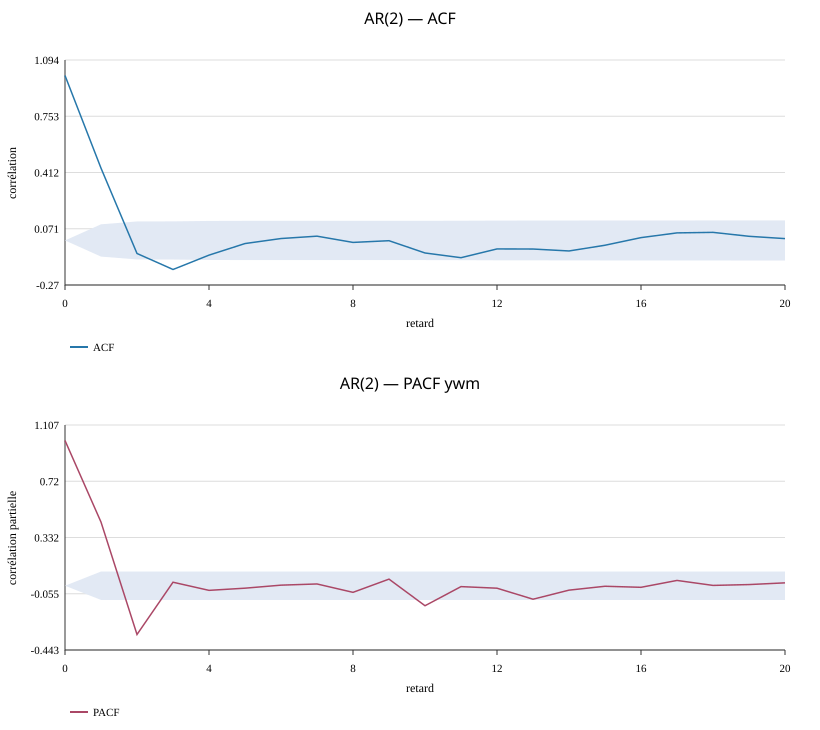

PACF retards1..5 : 0.438, -0.336, 0.024, -0.032, -0.017


Bande repère ±0.100 ; retards positifs hors bande : 1, 2, 10


Le retard zéro est exclu : corrélation avec soi-même =1. Les franchissements isolés ne constituent pas une sélection d'ordre certaine.


In [7]:
// Les innovations NumPy sont communes aux deux langues ; la récurrence AR(2) est calculée en C#.
// Les intervalles statsmodels sont distincts du repère approximatif2/sqrt(n), qui exclut le retard zéro.
double[] innovations;
using (Py.GIL())
{
    dynamic np = Py.Import("numpy");
    using PyObject z = np.random.default_rng(11).normal(0.0, 1.0, 398);
    innovations = Vector(z);
}

var ar2 = new double[400];
for (int i = 2; i < ar2.Length; i++)
    ar2[i] = .6 * ar2[i - 1] - .3 * ar2[i - 2] + innovations[i - 2];
var arCorr = Correlations(ar2, 20);
double arBand = 2 / Math.Sqrt(ar2.Length);
var acfBand = CorrelationInterval(ar2, 20);
var pacfBand = CorrelationInterval(ar2, 20, true);
AfficherSvg(new PlotSvg(Stack(new[] { Plot("AR(2) — ACF", new[] { ("ACF", arCorr.Acf, "#2677aa") }, "retard", "corrélation", interval: acfBand.CenteredIntervals), Plot("AR(2) — PACF ywm", new[] { ("PACF", arCorr.Pacf, "#aa4766") }, "retard", "corrélation partielle", interval: pacfBand.CenteredIntervals) })));
Console.WriteLine("PACF retards1..5 : " + string.Join(", ", arCorr.Pacf.Skip(1).Take(5).Select(x => x.ToString("F3"))));
Console.WriteLine($"Bande repère ±{arBand:F3} ; retards positifs hors bande : {string.Join(", ", Enumerable.Range(1, 20).Where(k => Math.Abs(arCorr.Pacf[k]) > arBand))}");
Console.WriteLine("Le retard zéro est exclu : corrélation avec soi-même =1. Les franchissements isolés ne constituent pas une sélection d'ordre certaine.");


### Interprétation de la PACF de l'AR(2)

Les estimations aux retards 1 et 2 sont voisines de **0,438** et **−0,336**, bien au-delà du repère ±0,100. Un autre franchissement apparaît au retard 10 : il ne suffit pas à transformer le générateur AR(2) connu en AR(10). C'est une illustration de l'incertitude et de la multiplicité des retards inspectés, pas une sélection automatique de modèle.

### Exercice 2 — calcul et lecture reproductibles des corrélogrammes

Complétez une fonction générique renvoyant Acf, Pacf ywm et SignificantLags, la liste ordonnée des retards **strictement positifs** dont |PACF| dépasse 2/√n. Contrôlez les ventes différenciées jusqu'au retard 40 et une autre série jusqu'au retard 10. Les tableaux sont contrôlés contre statsmodels ; les dimensions, valeurs finies et exclusion du retard zéro comptent. La liste est un diagnostic descriptif, pas un ordre p démontré.


In [8]:
record CorrelationAnswer(double[] Acf, double[] Pacf, int[] SignificantLags);
Func<double[], int, CorrelationAnswer> lireCorrelogramme = null; // TODO étudiant : ACF, PACF ywm et retards positifs hors bande 2/sqrt(n)
bool VerifyCorrelations(Func<double[], int, CorrelationAnswer> response)
{
    if (response == null)
        return false;
    foreach (var f in new[]
    {
        (values: Difference(sales), lags: 40),
        (values: ar2, lags: 10)
    }

    )
    {
        var a = response((double[])f.values.Clone(), f.lags);
        var r = Correlations(f.values, f.lags);
        var significant = Enumerable.Range(1, f.lags).Where(k => Math.Abs(r.Pacf[k]) > 2 / Math.Sqrt(f.values.Length)).ToArray();
        bool Equal(double[] x, double[] y) => x != null && x.Length == y.Length && x.All(double.IsFinite) && x.Zip(y, (v, z) => Math.Abs(v - z)).All(v => v < 1e-9);
        if (a == null || !Equal(a.Acf, r.Acf) || !Equal(a.Pacf, r.Pacf) || a.SignificantLags == null || !a.SignificantLags.SequenceEqual(significant))
            return false;
    }

    return true;
}

var salesCorr = Correlations(Difference(sales), 40);
Console.WriteLine("Repère calculé sur ventes différenciées, retards positifs PACF : " + string.Join(", ", Enumerable.Range(1, 40).Where(k => Math.Abs(salesCorr.Pacf[k]) > 2 / Math.Sqrt(sales.Length - 1))));
Console.WriteLine(lireCorrelogramme == null ? "Exercice 2 à compléter : deux tailles et horizons de corrélation, aucun ordre imposé par une seule barre." : $"Exercice 2 valide : {VerifyCorrelations(lireCorrelogramme)}");
if (lireCorrelogramme != null && VerifyCorrelations(lireCorrelogramme))
{
    var answer = lireCorrelogramme(Difference(sales), 40);
    AfficherSvg(new PlotSvg(Stack(new[] { Plot("Exercice2 — ACF des ventes différenciées", new[] { ("ACF réponse", answer.Acf, "#2677aa") }, "retard", "corrélation", interval: CorrelationInterval(Difference(sales), 40).CenteredIntervals), Plot("Exercice2 — PACF des ventes différenciées", new[] { ("PACF réponse", answer.Pacf, "#aa4766") }, "retard", "corrélation partielle", interval: CorrelationInterval(Difference(sales), 40, true).CenteredIntervals) })));
    Console.WriteLine("Lecture : retards positifs hors repère = " + string.Join(", ", answer.SignificantLags) + " ; le lag7 est un diagnostic à confronter aux autres retards, sans ordre certain.");
}


Repère calculé sur ventes différenciées, retards positifs PACF : 1, 2, 3, 4, 5, 6, 7, 9, 11, 12, 13, 16, 20, 21, 25, 26


Exercice 2 à compléter : deux tailles et horizons de corrélation, aucun ordre imposé par une seule barre.


## Partie 4 : ARIMA / SARIMA — ajuster, diagnostiquer, prévoir

Le diagnostic précédent motive l'étude de d=1. On fixe aussi D=1 et s=7 comme choix expérimental de cette grille : l'ADF non saisonnier ne démontre pas la présence d'une racine unité saisonnière. Les quatre ordres courts (p,q) et quatre couples saisonniers (P,Q), chacun dans {0,1}, donnent **16 ajustements** sur les 365 jours de 2023.

L'AIC classe ces configurations à données et différenciations communes ; la convergence numérique doit être examinée séparément. Les diagnostics résiduels et le test hors échantillon complètent ce critère. Aucun modèle qui échoue n'est remplacé silencieusement par la baseline.


Le backtest ci-dessous est conditionné aux choix **d=D=1 et s=7 fixés** ; il évalue les ajustements ainsi spécifiés, pas un processus complet de choix des transformations ignorant le futur.


In [9]:
// Les seize modèles partagent les mêmes données et différenciations pour comparer leur AIC.
// Le drapeau de convergence est rapporté séparément ; un AIC fini ne certifie pas à lui seul la convergence.
var configurations = new List<(int[] Order, int[] Seasonal, double Aic, bool Converged)>();
using (Py.GIL())
{
    foreach (int p in new[]
    {
        0,
        1
    }

    )
        foreach (int q in new[]
        {
            0,
            1
        }

        )
            foreach (int P in new[]
            {
                0,
                1
            }

            )
                foreach (int Q in new[]
                {
                    0,
                    1
                }

                )
                {
                    var order = new[]
                    {
                        p,
                        1,
                        q
                    };
                    var seasonal = new[]
                    {
                        P,
                        1,
                        Q,
                        7
                    };
                    using var model = FitSarima(train, order, seasonal);
                    double aic = Aic(model);
                    bool converged;
                    using (Py.GIL())
                    {
                        using PyObject info = ((dynamic)model).mle_retvals;
                        using var key = new PyString("converged");
                        converged = info.GetItem(key).As<bool>();
                    }

                    if (!double.IsFinite(aic))
                        throw new Exception("AIC non fini : aucun modèle de repli autorisé.");
                    configurations.Add((order, seasonal, aic, converged));
                }
}

var sorted = configurations.OrderBy(x => x.Aic).ToArray();
var bestOrder = sorted[0].Order;
var bestSeasonal = sorted[0].Seasonal;
foreach (var row in sorted.Take(8))
    Console.WriteLine($"SARIMA({string.Join(",", row.Order)}) × ({string.Join(",", row.Seasonal)}) AIC={row.Aic:F1}, convergence={row.Converged}");
Console.WriteLine($"Grille complète : {configurations.Count}/16 ajustements ; meilleur AIC {sorted[0].Aic:F1}. La convergence numérique est rapportée séparément du classement AIC.");


SARIMA(0,1,1) × (0,1,1,7) AIC=2666.7, convergence=True


SARIMA(1,1,1) × (0,1,1,7) AIC=2667.5, convergence=True


SARIMA(0,1,1) × (1,1,1,7) AIC=2668.5, convergence=True


SARIMA(1,1,1) × (1,1,1,7) AIC=2669.4, convergence=True


SARIMA(0,1,1) × (1,1,0,7) AIC=2781.8, convergence=True


SARIMA(1,1,1) × (1,1,0,7) AIC=2783.4, convergence=True


SARIMA(1,1,0) × (0,1,1,7) AIC=2813.6, convergence=True


SARIMA(1,1,0) × (1,1,1,7) AIC=2815.6, convergence=True


Grille complète : 16/16 ajustements ; meilleur AIC 2666.7. La convergence numérique est rapportée séparément du classement AIC.


### Prévision hors échantillon

La grille est classée sur le seul entraînement. La cellule suivante réajuste sa meilleure configuration et prévoit les **366 jours** de 2024, avec intervalle conditionnel à 95 % et MAPE sur les trente premiers jours.


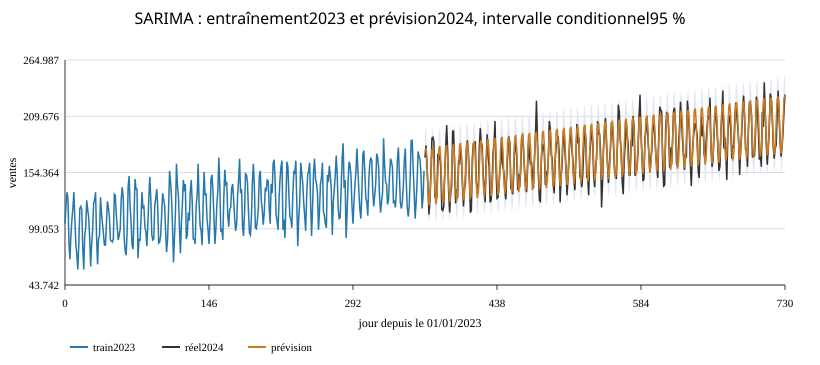

366 prévisions et intervalles ; AIC final 2666.7 ; MAPE30 jours 5.61 %


In [10]:
// La meilleure configuration est réajustée sur 2023 puis projette tout 2024 sans mise à jour sur le test.
// L’intervalle est conditionnel au modèle ; les longueurs, bornes ordonnées et valeurs finies sont vérifiées avant interprétation.
var finalSarima = FitSarima(train, bestOrder, bestSeasonal);
var prediction = ForecastInterval(finalSarima, test.Length);
var allTrain = train.Concat(Enumerable.Repeat(double.NaN, test.Length)).ToArray();
var allTest = Enumerable.Repeat(double.NaN, train.Length).Concat(test).ToArray();
var allForecast = Enumerable.Repeat(double.NaN, train.Length).Concat(prediction.Mean).ToArray();
Show("SARIMA : entraînement2023 et prévision2024, intervalle conditionnel95 %", new[] { ("train2023", allTrain, "#2677aa"), ("réel2024", allTest, "#333333"), ("prévision", allForecast, "#cb7b22") }, "jour depuis le 01/01/2023", "ventes", prediction.Interval, train.Length);
double sarimaMape30 = Mape(test.Take(30).ToArray(), prediction.Mean.Take(30).ToArray());
Console.WriteLine($"{test.Length} prévisions et intervalles ; AIC final {Aic(finalSarima):F1} ; MAPE30 jours {sarimaMape30:F2} %");
if (prediction.Mean.Length != 366 || prediction.Interval.Length != 366 || prediction.Interval.Any(row => row.Length != 2 || row[0] > row[1] || row.Any(v => !double.IsFinite(v))))
    throw new Exception("Prévision ou intervalle incomplet.");


### Diagnostics des résidus : une question à tester

On examine l'ACF des résidus et le test Ljung–Box aux retards 5 et 10. L'hypothèse nulle de ce test porte sur l'absence d'autocorrélation jusqu'au retard considéré ; son non-rejet ne démontre ni indépendance, ni normalité, ni bruit blanc. Comme le source, l'expérience conserve tous les résidus et model_df=0 : les degrés de liberté liés à l'ajustement et le démarrage du filtre sont des limites de cette lecture.


ACF résiduelle retards1..10 : 0.00, -0.02, 0.05, -0.14, 0.01, 0.13, -0.08, -0.05, 0.05, -0.05


Ljung-Box au retard 5 : p=0.109, absence d'autocorrélation non rejetée


Ljung-Box au retard 10 : p=0.031, rejet d'absence d'autocorrélation


Test comme le source : model_df=0, résidus complets incluant l'initialisation ; non-rejet ne démontre pas un bruit blanc.


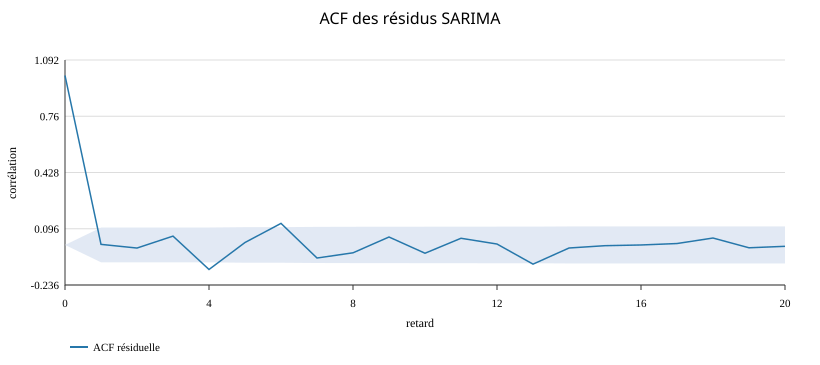

In [11]:
// Ljung–Box est calculé aux deux retards prescrits sur tous les résidus, avec model_df par défaut 0.
// Ce contrôle descriptif ne prouve ni indépendance ni normalité ; le graphique ACF expose les corrélations résiduelles.
double[] residuals;
double[] lbP;
using (Py.GIL())
{
    using PyObject r = ((dynamic)finalSarima).resid;
    residuals = Vector(r);
    dynamic diag = Py.Import("statsmodels.stats.diagnostic");
    using PyObject a = ArrayPy(residuals);
    using PyObject lags = JsonPy(new[] { 5, 10 });
    using PyObject result = diag.acorr_ljungbox(a, lags: lags, return_df: true);
    using var key = new PyString("lb_pvalue");
    using PyObject col = result.GetItem(key);
    lbP = Vector(col);
}

var residualCorr = Correlations(residuals, 20).Acf;
Console.WriteLine("ACF résiduelle retards1..10 : " + string.Join(", ", residualCorr.Skip(1).Take(10).Select(x => x.ToString("F2"))));
for (int j = 0; j < 2; j++)
    Console.WriteLine($"Ljung-Box au retard {new[] { 5, 10 }[j]} : p={lbP[j]:F3}, {(lbP[j] < .05 ? "rejet d'absence d'autocorrélation" : "absence d'autocorrélation non rejetée")}");
Console.WriteLine("Test comme le source : model_df=0, résidus complets incluant l'initialisation ; non-rejet ne démontre pas un bruit blanc.");
Show("ACF des résidus SARIMA", new[] { ("ACF résiduelle", residualCorr, "#2677aa") }, "retard", "corrélation", interval: CorrelationInterval(residuals, 20).CenteredIntervals);


### Interprétation des diagnostics

L'ACF présente notamment des valeurs proches de **−0,14 au retard 4** et **0,13 au retard 6**. Le Ljung–Box donne, dans le run, p ≈ **0,109** au retard 5 et **0,031** au retard 10 : absence d'autocorrélation non rejetée au premier, rejetée au second. Une petite p-value ne mesure pas la taille d'un effet ; ces résultats n'autorisent pas à certifier un bruit blanc ou une adéquation globale. L'intervalle de prévision est conditionnel au modèle ajusté, sans couvrir toute l'incertitude de sélection.

### Exercice 3 — vrai ARIMA sans saisonnalité

Complétez la prévision par ARIMA(1,1,1), sans terme saisonnier, pour les données et l'horizon reçus. Le garde compare les prévisions de deux séries et horizons différents au vrai moteur ; MAPE est recalculée depuis les prévisions, pas acceptée comme un chiffre déclaré. Comparez ensuite les 30 premiers jours au SARIMA sans imposer de gagnant général.


In [12]:
Func<double[], int, double[]> prevoirArima = null; // TODO étudiant : vrai ARIMA(1,1,1), puis prévision de l'horizon demandé
PyObject FitArima(double[] values)
{
    using (Py.GIL())
    {
        dynamic sm = Py.Import("statsmodels.tsa.arima.model");
        using PyObject a = ArrayPy(values);
        using PyObject o = JsonPy(new[] { 1, 1, 1 });
        using PyObject model = sm.ARIMA(a, order: o);
        return ((dynamic)model).fit();
    }
}

bool VerifyArima(Func<double[], int, double[]> response)
{
    if (response == null)
        return false;
    foreach (var f in new[]
    {
        (values: train, steps: 30),
        (values: ar2.Take(100).Select(x => 100 + 2 * x).ToArray(), steps: 7)
    }

    )
    {
        using (Py.GIL())
        {
            var actual = response((double[])f.values.Clone(), f.steps);
            using var model = FitArima(f.values);
            var expected = Forecast(model, f.steps);
            if (actual == null || actual.Length != expected.Length || actual.Any(v => !double.IsFinite(v)) || actual.Zip(expected, (a, b) => Math.Abs(a - b)).Any(v => v > 1e-7))
                return false;
        }
    }

    return true;
}

if (prevoirArima == null)
    Console.WriteLine("Exercice 3 à compléter : vrai ARIMA sans terme saisonnier, deux fixtures et horizons.");
else
{
    Console.WriteLine($"Exercice 3 valide : {VerifyArima(prevoirArima)}");
    Console.WriteLine($"MAPE ARIMA30j {Mape(test.Take(30).ToArray(), prevoirArima(train, 30)):F2} % contre SARIMA {sarimaMape30:F2} % ; ce seul contraste ne prouve pas une domination générale.");
}


Exercice 3 à compléter : vrai ARIMA sans terme saisonnier, deux fixtures et horizons.


## Partie 5 : Lissage exponentiel — simple / Holt / Holt-Winters

Le lissage exponentiel pondère les observations passées avec des poids décroissants. SimpleExpSmoothing représente le niveau ; Holt ajoute une tendance ; Holt–Winters ajoute une composante saisonnière. On ajuste les trois vraies classes statsmodels sur les mêmes 365 jours, puis on prévoit les 30 premiers jours de 2024. La forme additive et la période 7 sont des choix explicites ; elles ne sont pas automatiquement correctes pour toute série hebdomadaire.


HW : AIC interne 1658.5 ; MAPE30j 5.61 %


Holt : AIC interne 2313.7 ; MAPE30j 17.50 %


Simple : AIC interne 2288.9 ; MAPE30j 16.63 %


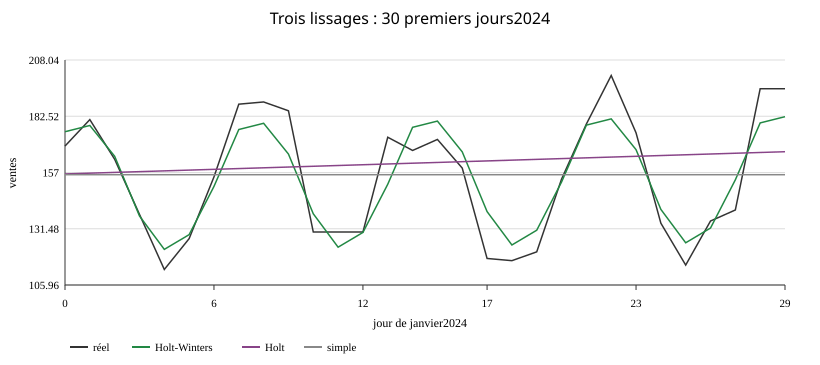

Les AIC affichés ont leur définition de vraisemblance propre à la famille ; la comparaison inter-familles s'appuie ici sur MAPE hors échantillon.


In [13]:
// Les trois lissages utilisent le même train et les mêmes trente observations de test.
// Leurs AIC ne sont pas directement comparables entre familles ; la MAPE reste le critère commun hors échantillon.
var smoothPredictions = new Dictionary<string, double[]>();
using (Py.GIL())
    foreach (var kind in new[]
    {
        "HW",
        "Holt",
        "Simple"
    }

    )
    {
        using var model = FitSmoothing(train, kind);
        var fc = Forecast(model, 30);
        smoothPredictions[kind] = fc;
        Console.WriteLine($"{kind} : AIC interne {Aic(model):F1} ; MAPE30j {Mape(test.Take(30).ToArray(), fc):F2} %");
    }

Show("Trois lissages : 30 premiers jours2024", new[] { ("réel", test.Take(30).ToArray(), "#333333"), ("Holt-Winters", smoothPredictions["HW"], "#228844"), ("Holt", smoothPredictions["Holt"], "#884488"), ("simple", smoothPredictions["Simple"], "#888888") }, "jour de janvier2024", "ventes");
Console.WriteLine("Les AIC affichés ont leur définition de vraisemblance propre à la famille ; la comparaison inter-familles s'appuie ici sur MAPE hors échantillon.");


### Interprétation — comparaison hors échantillon

Sur les 30 premiers jours du run, Holt–Winters et SARIMA ont des MAPE proches de **5,6 %**, contre environ **17,5 %** pour Holt et **16,6 %** pour le lissage simple. Ce résultat descriptif concerne cette fenêtre et ces réglages ; il motive une comparaison multi-fenêtre. Holt–Winters estime aussi des états initiaux et une structure saisonnière, pas seulement trois nombres. Les AIC internes affichés ne sont pas utilisés pour classer des familles à conventions de vraisemblance différentes.

## Partie 6 : Comparaison honnête — backtest expansif

On garde **12 fenêtres de 7 jours**, soit 84 jours de test. Chaque modèle est réajusté sur le passé disponible, avec les ordres SARIMA sélectionnés sur 2023 ; aucune observation future n'entre dans les ajustements de ces modèles conditionnés aux choix fixés. Le naïf répète la dernière valeur observée. Le choix de sept jours expose le cycle hebdomadaire ; il ne prétend pas que toutes les prévisions à un jour seraient identiques. Une égalité après arrondi à deux décimales n'est pas une équivalence statistique démontrée.


Les diagnostics globaux précédents ont vu2024. La séparation des données d’ajustement ne prouve donc pas ici l’absence de fuite d’un **pipeline entier de sélection** ; cette limite est distincte de l’intégrité des douze réajustements sur le passé.


In [14]:
// Chaque fenêtre réajuste les deux modèles sur le passé disponible puis prévoit sept jours.
// Les ordres restent ceux choisis sur 2023 ; le compteur de victoires accepte les ex aequo après arrondi.
record FoldScore(int Fold, int PastLength, double Naive, double HoltWinters, double Sarima);
List<FoldScore> Backtest(int folds)
{
    var rows = new List<FoldScore>();
    for (int k = 0; k < folds; k++)
    {
        int idx = train.Length + 7 * k;
        if (idx + 7 > sales.Length)
            break;
        var past = sales.Take(idx).ToArray();
        var truth = sales.Skip(idx).Take(7).ToArray();
        var naive = Enumerable.Repeat(past[^1], 7).ToArray();
        using (Py.GIL())
        {
            using var hw = FitSmoothing(past, "HW");
            using var sar = FitSarima(past, bestOrder, bestSeasonal);
            rows.Add(new FoldScore(k + 1, past.Length, Mape(truth, naive), Mape(truth, Forecast(hw, 7)), Mape(truth, Forecast(sar, 7))));
        }
    }

    return rows;
}

var foldScores = Backtest(12);
foreach (var f in foldScores)
    Console.WriteLine($"fold{f.Fold, 2}, passé={f.PastLength} : naïf {f.Naive:F2} % | HW {f.HoltWinters:F2} % | SARIMA {f.Sarima:F2} %");
Console.WriteLine($"12 fenêtres×7jours : moyennes naïf {foldScores.Average(x => x.Naive):F2} %, HW {foldScores.Average(x => x.HoltWinters):F2} %, SARIMA {foldScores.Average(x => x.Sarima):F2} %");
int[] wins = new int[3];
foreach (var f in foldScores)
{
    var scores = new[]
    {
        f.Naive,
        f.HoltWinters,
        f.Sarima
    }.Select(x => Math.Round(x, 2, MidpointRounding.ToEven)).ToArray();
    double best = scores.Min();
    for (int j = 0; j < 3; j++)
        if (scores[j] == best)
            wins[j]++;
}

Console.WriteLine($"Meilleurs à 0,01point près (ex aequo possibles) : naïf {wins[0]}, HW {wins[1]}, SARIMA {wins[2]}. Aucun repli silencieux : chaque ligne résulte des deux vrais ajustements.");


fold 1, passé=365 : naïf 14.34 % | HW 2.71 % | SARIMA 2.71 %


fold 2, passé=372 : naïf 17.12 % | HW 6.63 % | SARIMA 6.63 %


fold 3, passé=379 : naïf 23.25 % | HW 7.17 % | SARIMA 7.17 %


fold 4, passé=386 : naïf 17.47 % | HW 5.70 % | SARIMA 5.70 %


fold 5, passé=393 : naïf 15.58 % | HW 7.26 % | SARIMA 7.26 %


fold 6, passé=400 : naïf 14.64 % | HW 4.71 % | SARIMA 4.71 %


... (4 outputs left out)

fold11, passé=435 : naïf 18.75 % | HW 5.24 % | SARIMA 5.24 %


fold12, passé=442 : naïf 9.59 % | HW 6.21 % | SARIMA 6.21 %


12 fenêtres×7jours : moyennes naïf 15.98 %, HW 5.82 %, SARIMA 5.82 %


Meilleurs à 0,01point près (ex aequo possibles) : naïf 0, HW 12, SARIMA 12. Aucun repli silencieux : chaque ligne résulte des deux vrais ajustements.


### Interprétation du backtest

Le run donne environ **15,98 %** de MAPE au naïf contre **5,82 %** aux deux modèles saisonniers, à la précision de l'affichage. Les victoires par fenêtre comptent les ex aequo : leur somme peut dépasser douze. Cette proximité ne prouve ni identité des prévisions ni absence générale de gain à utiliser SARIMA. La configuration sélectionnée a ici p=0 : attribuer son écart à un « ordre AR ajouté » serait même inexact. La conclusion utile est limitée : sur ces douze fenêtres et ces configurations, le modèle plus complexe n'apporte pas de gain visible à la précision retenue. Un autre horizon, une autre série et une estimation d'incertitude pourraient changer cette lecture.

### Exercice 4 — bonus 24 fenêtres

Rejouez le même protocole expansif sur 24 fenêtres de sept jours, sans changer les données ni regarder le futur. Renvoyez les tailles de passé et les trois erreurs par fenêtre ; une observation textuelle seule ne prouve pas les réajustements. Comparez les moyennes et ex aequo au protocole à douze fenêtres, sans imposer le résultat.


In [15]:
List<FoldScore> observation24 = null; // TODO étudiant : exécuter le backtest expansif sur 24 fenêtres, puis interpréter
bool Verify24(List<FoldScore> response)
{
    if (response == null || response.Count != 24 || response.Where((r, i) => r.Fold != i + 1 || r.PastLength != train.Length + 7 * i || !double.IsFinite(r.Naive) || !double.IsFinite(r.HoltWinters) || !double.IsFinite(r.Sarima)).Any())
        return false;
    var expected = Backtest(24);
    return response.Zip(expected, (a, b) => Math.Abs(a.Naive - b.Naive) < 1e-8 && Math.Abs(a.HoltWinters - b.HoltWinters) < 1e-6 && Math.Abs(a.Sarima - b.Sarima) < 1e-6).All(x => x);
}

Console.WriteLine(observation24 == null ? "Exercice4 bonus à compléter : 24 fenêtres effectives, pas une observation textuelle fabriquée." : $"24 fenêtres vérifiées : {Verify24(observation24)}");


Exercice4 bonus à compléter : 24 fenêtres effectives, pas une observation textuelle fabriquée.


## Conclusion et pont vers la suite

Ce carnet relie six activités : décomposer ; examiner une racine unité ; lire ACF/PACF ; ajuster SARIMA et diagnostiquer ses résidus ; comparer les trois lissages ; tester hors échantillon sur un passé expansif. Les diagnostics orientent les choix, sans produire de preuve universelle de stationnarité ou de domination d'un modèle.

| Direction | Carnet | Prolongement |
|---|---|---|
| SSA en ML.NET | [ML-05 C#](ML-05-TimeSeries-CSharp.ipynb) | autre modèle natif, qui ne remplace pas ADF/SARIMA |
| Application STL/SARIMA | [ML-05 Python](ML-05-TimeSeries-Python.ipynb) | application et intervalles |
| Famille quant | [Index QuantConnect](../../QuantConnect/README.md) | protocoles hors échantillon et modèles temporels |

## À retenir

ADF non rejeté ne prouve pas H0 ; un seuil d'ACF/PACF ne sélectionne pas seul un ordre ; une p-value résiduelle ne certifie pas un bruit blanc ; un arrondi commun ne prouve pas l'équivalence de deux prévisions. Les modèles réels et le backtest sans repli rendent ces limites vérifiables.

## Vérifiez votre compréhension

1. Un cycle de sept jours impose-t-il D=1 ?
<details><summary>Réponse</summary>Non : saisonnalité déterministe et racine unité saisonnière sont distinctes ; la grille fixe D=1 comme choix à évaluer.</details>

2. Pourquoi exclure le retard zéro de la liste PACF ?
<details><summary>Réponse</summary>Il vaut 1 par définition et ne diagnostique pas une relation entre dates distinctes.</details>

3. Deux MAPE affichées à 5,82 % prouvent-elles des prévisions identiques ?
<details><summary>Réponse</summary>Non : l'arrondi masque des différences et le protocole n'établit pas une équivalence statistique.</details>

## Pour aller plus loin

Comparer d'autres horizons, contrôler une différenciation saisonnière et ajuster les degrés de liberté du diagnostic ; suivre les trois liens du tableau pour les applications.
